# Experiment Results Collected

## What we collect

| Detail | Info |
| --- | --- |
| Sample | **179 GBIF Datasets: `ID`, `Nr Data Files`, `PDF Bytes`, `PDF Nr Pages`, `DDir`** |
| Independent Variable | **Metadata Schema: `DwC-T`, `EML`** |
| Treatment | **_massi_: w/ `Data File Provider`, w/ `Data Paper Provider`** |
| Dependent Variables | **`Nr Parseable`, `COR`, `SIMstr`, `SIMsemT`, `SIMsemA`** |
| Supporting Insights | **`success`, `size`, `size+a`, `depth`, `out`, `JIPn`, `JIPp`, `APTEDsim`, `APTEDbr`** |

In [1]:
!cd ../../.. && pip install -v . --group=dev --group=observability --group=analysis

Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
Processing ./.
  Running command installing build dependencies
  Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/95/9c/c510029fc6ef33a6275cd2c5d3cecd6613dfd6aa401d57c54f1c18852ccf/setuptools-84.0.0-py3-none-any.whl.metadata
    Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached setuptools-84.0.0-py3-none-any.whl (818 kB)
  ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
  torch 2.12.0 requires setuptools<82, but you have setuptools 84.0.0 which is incompatible.
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  r

In [2]:
import warnings
from lxml import etree
import apted
import massi.agents.tools as matls
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import tol_colors as tcls
import itertools as itlx
import json
from pathlib import Path
import re 
from typing import TypedDict, Any
from IPython.display import display, display_markdown
from pprint import pprint

In [3]:
from sklearn.metrics.pairwise import cosine_similarity
COS_SIMILARITY_READY = False
try:
    # NOTE: this can not run natively on Intel mac anymore
    from sentence_transformers import SentenceTransformer
    COS_SIMILARITY_READY = True
except ImportError as e:
    COS_SIMILARITY_READY = False
    warnings.warn("FAILED TO IMPORT `sentence_transformers`")
    warnings.warn(str(e))
finally:
    print(f"{COS_SIMILARITY_READY=}")

COS_SIMILARITY_READY=True


In [4]:
from scipy.stats import mannwhitneyu, ttest_ind, normaltest

In [5]:
def cohen_d(s1, s2):
    """
    Computes Cohen's d for two pandas Series / numpy arrays.
    """
    n1, n2 = len(s1), len(s2)
    m1, m2 = np.mean(s1), np.mean(s2)
    v1, v2 = np.var(s1, ddof=1), np.var(s2, ddof=1)
    
    # Pooled standard deviation
    s_pooled = np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2))
    
    if s_pooled == 0:
        return np.nan
        
    return (m1 - m2) / s_pooled

In [6]:
tcls.set_default_colors()
plt.set_cmap(mpl.cm.tab20)

New config line: axes.prop_cycle : cycler('color', ['4477AA', 'EE6677', '228833', 'CCBB44', '66CCEE', 'AA3377', 'BBBBBB'])
Injecting line in file '/Users/mitjaorlov/.matplotlib/matplotlibrc'


<Figure size 640x480 with 0 Axes>

In [7]:
# pd.set_option('display.max_colwidth', None)

## Utilities

Some tools for frequent operations and convenience.

In [8]:
EXPERIMENT_BASE_DIR = "../../../_data/gbif_data_archive/"

def grounded_path(suffix: str | Path) -> Path:
    return Path(EXPERIMENT_BASE_DIR) / suffix

### Data Analyses: DuckDB

Setting up DuckDB for use in the notebook.

In [12]:
from duckdb.sqltypes import VARCHAR
import duckdb as ddb

In [13]:
%config SqlMagic.autopandas = True
%load_ext sql
conn = ddb.connect()
%sql conn --alias duckdb

The 'toml' package isn't installed. To load settings from pyproject.toml or ~/.jupysql/config, install with: pip install toml

## Step 0: Prepare Local Table

In [14]:
%%sql
CREATE OR REPLACE TABLE experiment_log AS 
    FROM "../../runtime/experiment_cross_scenarios_cases.log.csv";

Running query in 'duckdb'

,Count
0,716


In [15]:
%%sql experiment_log <<
SELECT * FROM experiment_log

Running query in 'duckdb'

In [16]:
experiment_log.columns

Index(['Unnamed: 0_x', 'variant', 'schema', 'strategy', 'provider', 'config',
       'scenario_id', 'scenario_tag', 'Unnamed: 0_y', 'title', 'authors',
       'source', 'published', 'open_access', 'peer_review', 'citation_type',
       'countries_of_coverage', 'countries_of_researcher', 'keywords',
       'literature_type', 'websites', 'identifiers', 'id', 'topics', 'added',
       'gbif_download_key', 'gbif_data_id_data', 'dwca_url', 'data_standard',
       'doi_url', 'genre', 'has_repository_copy', 'is_oa', 'journal_name',
       'published_date', 'publisher', 'best_oa_location.endpoint_id',
       'best_oa_location.oa_date', 'best_oa_location.url',
       'best_oa_location.url_for_landing_page', 'best_oa_location.url_for_pdf',
       'paper_download_file_path', 'dwca_download_path', 'dwca_zip_info',
       'paper_download_info', 'working_copy_data_dir',
       'ground_truth_paper_path', 'ground_truth_metadata_dir',
       'ground_truth_metadata_eml', 'ground_truth_metadata_dwc', 'ca

## Step 1: Sample, IV, Treatment Data Info

In [71]:
%%sql experiment_cases <<
WITH prep_gbif_cases AS (
    SELECT 
        case_id,
        "schema" as mschema,
        "strategy" as treatment,
        replace(
            replace(treatment, 'data-focus', 'data-file-provider'),
            'author-focus', 'data-paper-provider'
        ) as treatment_repl,
        replace(
            replace(
                replace(
                    dwca_zip_info, '''', '"'
                ), 'False', 'false'
            ), 'True', 'true'
        ) AS j_dwca_info,
        replace(
            replace(
                replace(
                    paper_download_info, '''', '"'
                ), 'False', 'false'
            ), 'True', 'true'
        ) AS j_paper_info,
        json_extract(
            j_dwca_info, 
            '$.nr_xml_files'
        ) AS nr_xml_files,
        json_extract(
            j_dwca_info, 
            '$.total_file_count'
        ) AS nr_all_files,
        (nr_all_files::INT - nr_xml_files::INT) AS nr_data_files, 
        json_extract(
            j_paper_info, 
            '$.file_size_bytes'
        ) AS pdf_bytes, 
        json_extract(
            j_paper_info, 
            '$.nr_pages'
        ) AS pdf_nr_pages,
        working_copy_data_dir as ddir,
    -- FROM "../../runtime/gbif_cases.csv"
    FROM experiment_log
)
SELECT 
    case_id, 
    mschema, 
    treatment,
    treatment_repl,
    nr_data_files::INT as nr_data_files, 
    pdf_bytes::INT as pdf_bytes, 
    pdf_nr_pages::INT as pdf_nr_pages, 
    ddir
FROM prep_gbif_cases;

Running query in 'duckdb'

In [72]:
experiment_cases.head()

,case_id,mschema,treatment,treatment_repl,nr_data_files,pdf_bytes,pdf_nr_pages,ddir
0,0,dwc,data-focus,data-file-provider,2,486786,14,working_copy/data/000-6f97bcef-7324-3425-bb72-...
1,1,dwc,data-focus,data-file-provider,1,700648,20,working_copy/data/001-2fee34a0-a302-3c12-8916-...
2,2,dwc,data-focus,data-file-provider,2,408932,18,working_copy/data/002-325b19cf-6c16-3147-b8db-...
3,3,dwc,data-focus,data-file-provider,2,918075,20,working_copy/data/003-d72b6b4f-0fb1-301e-81d0-...
4,4,dwc,data-focus,data-file-provider,3,516962,19,working_copy/data/004-93ed8a30-2f05-37c7-a371-...


In [73]:
experiment_cases.describe(include="all")

,case_id,mschema,treatment,treatment_repl,nr_data_files,pdf_bytes,pdf_nr_pages,ddir
count,716.000000,716,716,716,716.000000,7.160000e+02,716.000000,716
unique,NaN,2,2,2,NaN,NaN,NaN,179
top,NaN,dwc,data-focus,data-file-provider,NaN,NaN,NaN,working_copy/data/000-6f97bcef-7324-3425-bb72-...
freq,NaN,358,358,358,NaN,NaN,NaN,4
mean,89.000000,NaN,NaN,NaN,1.569832,1.097365e+06,14.134078,NaN
std,51.708164,NaN,NaN,NaN,0.701156,1.216402e+06,8.795034,NaN
min,0.000000,NaN,NaN,NaN,1.000000,4.090000e+02,1.000000,NaN
25%,44.000000,NaN,NaN,NaN,1.000000,3.777540e+05,9.000000,NaN
50%,89.000000,NaN,NaN,NaN,1.000000,6.099190e+05,13.000000,NaN
75%,134.000000,NaN,NaN,NaN,2.000000,1.495143e+06,18.000000,NaN


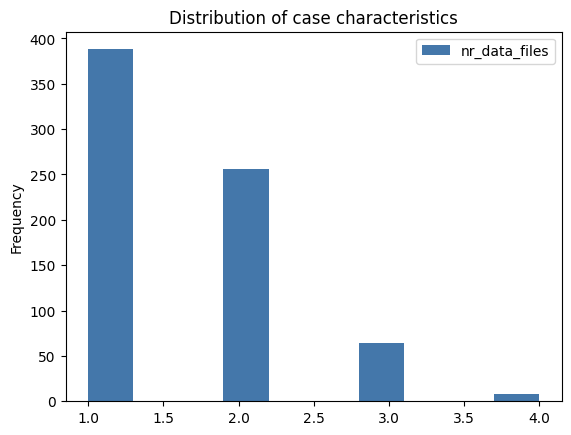

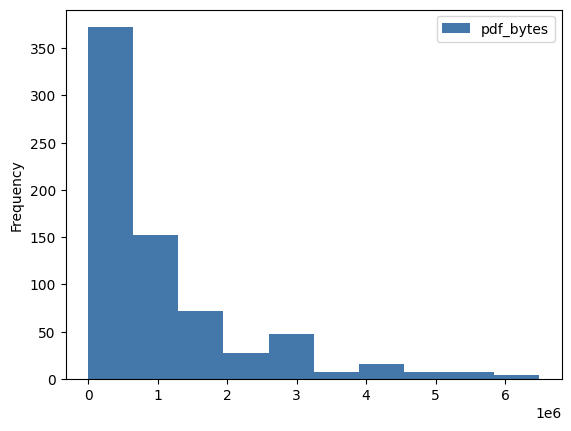

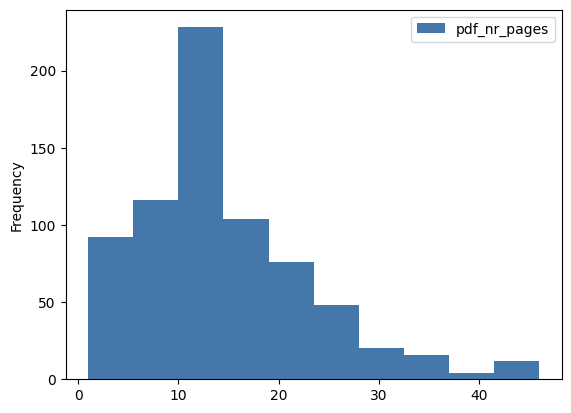

In [74]:
ax = experiment_cases.plot.hist(y="nr_data_files")
ax.set_title("Distribution of case characteristics")
experiment_cases.plot.hist(y="pdf_bytes")
experiment_cases.plot.hist(y="pdf_nr_pages")
plt.show()

In [75]:
experiment_cases[[
    "nr_data_files",
    "pdf_bytes",
    "pdf_nr_pages",
]].corr("pearson")

,nr_data_files,pdf_bytes,pdf_nr_pages
nr_data_files,1.000000,0.164903,0.100086
pdf_bytes,0.164903,1.000000,0.077866
pdf_nr_pages,0.100086,0.077866,1.000000


In [76]:
experiment_cases.to_csv("procedural_data/experiment_cases.csv")

In [77]:
experiment_cases.describe()

,case_id,nr_data_files,pdf_bytes,pdf_nr_pages
count,716.000000,716.000000,7.160000e+02,716.000000
mean,89.000000,1.569832,1.097365e+06,14.134078
std,51.708164,0.701156,1.216402e+06,8.795034
min,0.000000,1.000000,4.090000e+02,1.000000
25%,44.000000,1.000000,3.777540e+05,9.000000
50%,89.000000,1.000000,6.099190e+05,13.000000
75%,134.000000,2.000000,1.495143e+06,18.000000
max,178.000000,4.000000,6.490174e+06,46.000000


In [79]:
# One sample for all four configurations:
for name, group in experiment_cases.groupby(["mschema","treatment_repl"]):
    display(name)
    display(group.describe())

('dwc', 'data-file-provider')

,case_id,nr_data_files,pdf_bytes,pdf_nr_pages
count,179.000000,179.000000,1.790000e+02,179.000000
mean,89.000000,1.569832,1.097365e+06,14.134078
std,51.816986,0.702632,1.218962e+06,8.813544
min,0.000000,1.000000,4.090000e+02,1.000000
25%,44.500000,1.000000,3.787995e+05,9.000000
50%,89.000000,1.000000,6.099190e+05,13.000000
75%,133.500000,2.000000,1.490002e+06,18.000000
max,178.000000,4.000000,6.490174e+06,46.000000


('dwc', 'data-paper-provider')

,case_id,nr_data_files,pdf_bytes,pdf_nr_pages
count,179.000000,179.000000,1.790000e+02,179.000000
mean,89.000000,1.569832,1.097365e+06,14.134078
std,51.816986,0.702632,1.218962e+06,8.813544
min,0.000000,1.000000,4.090000e+02,1.000000
25%,44.500000,1.000000,3.787995e+05,9.000000
50%,89.000000,1.000000,6.099190e+05,13.000000
75%,133.500000,2.000000,1.490002e+06,18.000000
max,178.000000,4.000000,6.490174e+06,46.000000


('eml', 'data-file-provider')

,case_id,nr_data_files,pdf_bytes,pdf_nr_pages
count,179.000000,179.000000,1.790000e+02,179.000000
mean,89.000000,1.569832,1.097365e+06,14.134078
std,51.816986,0.702632,1.218962e+06,8.813544
min,0.000000,1.000000,4.090000e+02,1.000000
25%,44.500000,1.000000,3.787995e+05,9.000000
50%,89.000000,1.000000,6.099190e+05,13.000000
75%,133.500000,2.000000,1.490002e+06,18.000000
max,178.000000,4.000000,6.490174e+06,46.000000


('eml', 'data-paper-provider')

,case_id,nr_data_files,pdf_bytes,pdf_nr_pages
count,179.000000,179.000000,1.790000e+02,179.000000
mean,89.000000,1.569832,1.097365e+06,14.134078
std,51.816986,0.702632,1.218962e+06,8.813544
min,0.000000,1.000000,4.090000e+02,1.000000
25%,44.500000,1.000000,3.787995e+05,9.000000
50%,89.000000,1.000000,6.099190e+05,13.000000
75%,133.500000,2.000000,1.490002e+06,18.000000
max,178.000000,4.000000,6.490174e+06,46.000000


## Step 2: `+` Supporting Insights

### Tree Operations

In [82]:
def parse_xml_file(path: str | Path):
    return etree.parse(path)

def parse_xml_string(data: str):
    return etree.fromstring(data.encode())

def parse_xml_content(xml_content: Any):
    return parse_xml_string(str(xml_content))

def resolve_xml_content(r: dict) -> str:
    return r['resolutions'][0]['working_copy_xml_blueprint']["content"]    

def cleanup_gap_failures(xml_data:str):
    return re.sub(r"\{\{GAP_([0-9]+)[^\}]*\}+", r"not-derived-\1", xml_data)

def cleanup_special_characters(xml_data:str):
    return re.sub("&", "&amp;", xml_data)

In [80]:
class NodeInfo(TypedDict):
    tag: str
    degree: int
    depth: int
    is_leaf: bool # <=> (degree == 0) 
    attributes: str # <-- json.dumps(attributes)
    attributes_count: int # <-- |attributes.keys()|
    text: str
    path: str | None

class TreeInfo(TypedDict):
    size: int # <-- |_nodes|
    size_with_attributes: int # <-- SUM(n.attributes_count for n in _nodes)
    _nodes: list[NodeInfo]

def project_public(d: dict):
    public_data = {k:v for k,v in d.items() if not str(k).startswith("_")}
    return public_data

In [81]:
def get_root(tree):
    """Retrieves a root of the provided tree"""
    if hasattr(tree, "getroot"):
        return tree.getroot()
    return tree

def get_tree_info(tree) -> TreeInfo:
    return _get_tree_info(tree)

def _get_tree_info(tree) -> TreeInfo:
    root = etree.ElementTree(get_root(tree))
    
    def _get_node_info(node) -> NodeInfo:
        return {
            "tag": node.tag,
            "depth": len(list(node.iterancestors())),
            "degree": len(node),
            "is_leaf": len(node) == 0,
            "attributes": json.dumps(dict(node.attrib.items())),
            "attributes_count": len(node.attrib.keys()),
            "has_attributes": bool(node.attrib),
            "text": node.text,
            "has_text": bool(node.text.strip()) if node.text else False,
            "path": None if isinstance(node, etree._Comment) else root.getelementpath(node)
        }
    
    nodes_info = list(map(_get_node_info, root.iter()))
    return {
        "size": len(nodes_info), 
        "size_with_attributes": len(nodes_info) + sum(n["attributes_count"] for n in nodes_info),
        "_nodes": nodes_info
    }

### Computing

In [83]:
def outcome_json_to_tree_info_json(outcome_json: str) -> str:
    outcome_dict = json.loads(outcome_json)
    if ('resolutions' not in outcome_dict):
        return json.dumps({'parsed': False, 'tree_info': None, 'error': "'resolutions' key is not found"})
    try:
        wc_metadata_xml = resolve_xml_content(outcome_dict)
        wc_metadata_xml_clean = cleanup_special_characters(cleanup_gap_failures(wc_metadata_xml))
        wc_metadata_tree = parse_xml_content(wc_metadata_xml_clean)
        wc_metadata_tree_info = get_tree_info(wc_metadata_tree)
        return json.dumps({'parsed': True, 'tree_info': wc_metadata_tree_info, 'error': None})
    except Exception as e:
        return json.dumps({'parsed': False, 'tree_info': None, 'error': str(e)})

In [84]:
try:
    conn.remove_function("outcome_json_to_tree_info_json")
except Exception as e:
    print(e)
conn.create_function("outcome_json_to_tree_info_json", outcome_json_to_tree_info_json)

In [85]:
%%sql
CREATE OR REPLACE TABLE prep_gbif_cases AS (
-- WITH prep_gbif_cases AS (
    SELECT 
    -- experiment run details
        case_id,
        "schema" as mschema,
        "strategy" as treatment,
        replace(
            replace(treatment, 'data-focus', 'data-file-provider'),
            'author-focus', 'data-paper-provider'
        ) as treatment_repl,
        replace(
            replace(
                replace(
                    dwca_zip_info, '''', '"'
                ), 'False', 'false'
            ), 'True', 'true'
        ) AS j_dwca_info,
        replace(
            replace(
                replace(
                    paper_download_info, '''', '"'
                ), 'False', 'false'
            ), 'True', 'true'
        ) AS j_paper_info,
        json_extract(
            j_dwca_info, 
            '$.nr_xml_files'
        ) AS nr_xml_files,
        json_extract(
            j_dwca_info, 
            '$.total_file_count'
        ) AS nr_all_files,
        (nr_all_files::INT - nr_xml_files::INT) AS nr_data_files, 
        json_extract(
            j_paper_info, 
            '$.file_size_bytes'
        ) AS pdf_bytes, 
        json_extract(
            j_paper_info, 
            '$.nr_pages'
        ) AS pdf_nr_pages,
        working_copy_data_dir as ddir,
    
    -- supporting details
        success,
        outcome_json,
        outcome_json_to_tree_info_json(outcome_json) as tree_info_json,
        json_extract(tree_info_json, '$.parsed')::BOOLEAN as parsed,
        json_extract(tree_info_json, '$.tree_info.size')::INT as tree_size,
        json_extract(tree_info_json, '$.tree_info.size_with_attributes')::INT as tree_size_with_attrs,
        json_extract(tree_info_json, '$.tree_info._nodes') as tree_nodes
    FROM experiment_log
);
CREATE OR REPLACE TABLE experiment_constructed_tree_info_grand AS 
    SELECT 
        case_id, 
        mschema, 
        treatment,
        treatment_repl,
        nr_data_files::INT as nr_data_files, 
        pdf_bytes::INT as pdf_bytes, 
        pdf_nr_pages::INT as pdf_nr_pages, 
        ddir,
        success,
        outcome_json,
        tree_info_json,
        parsed,
        parsed::INT as parsed_int, 
        tree_size,
        tree_size_with_attrs,
        tree_nodes
    FROM prep_gbif_cases;
CREATE OR REPLACE TABLE experiment_constructed_tree_info_nodes AS 
    SELECT 
        case_id, 
        mschema, 
        treatment,
        treatment_repl,
        nr_data_files::INT as nr_data_files, 
        pdf_bytes::INT as pdf_bytes, 
        pdf_nr_pages::INT as pdf_nr_pages, 
        ddir,
        success,
        outcome_json,
        tree_info_json,
        parsed,
        je.*,
        json_extract(je.value, '$.tag') as node_tag,
        json_extract(je.value, '$.depth')::INT as node_depth,
        json_extract(je.value, '$.degree')::INT as node_degree,
    FROM prep_gbif_cases AS c,
        json_each(c.tree_nodes) AS je
    WHERE parsed = True;

Running query in 'duckdb'

,Count
0,29417


> **Trees details**

In [86]:
%%sql experiment_tree_info_grand <<
SELECT * 
FROM experiment_constructed_tree_info_grand

Running query in 'duckdb'

In [87]:
experiment_tree_info_grand['log_pdf_bytes'] = np.log1p(experiment_tree_info_grand['pdf_bytes'])

In [88]:
experiment_groups_tree = experiment_tree_info_grand.groupby(["mschema", "treatment_repl"])

["('dwc', 'data-file-provider')" "('dwc', 'data-paper-provider')"
 "('eml', 'data-file-provider')" "('eml', 'data-paper-provider')"]
[179 179 179 179]


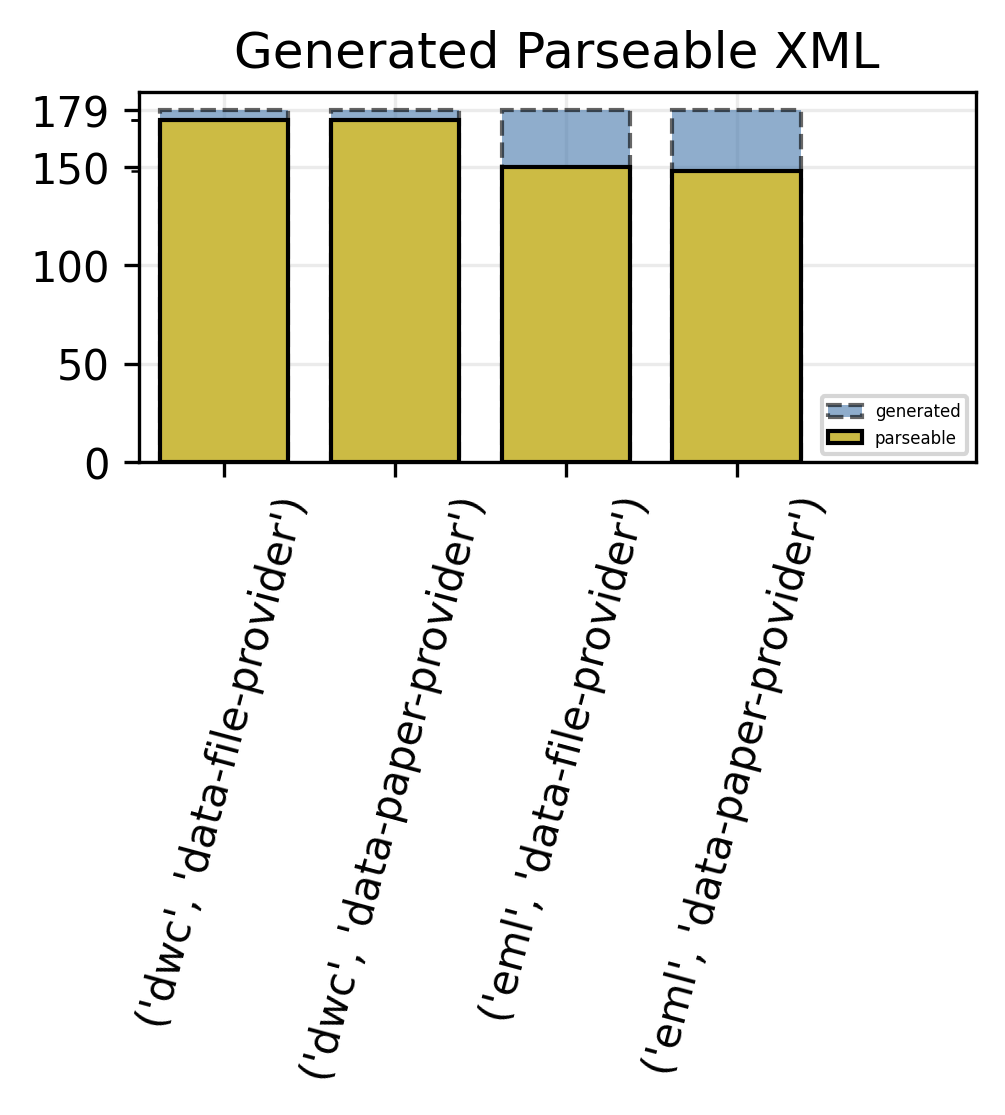

In [93]:
fig, ax = plt.subplots(1,1, dpi=300, figsize=(3.6, 1.6))

experiment_groups = np.array([str(g) for g, rs in experiment_groups_tree])
experiment_count = np.array([rs.shape[0] for g, rs in experiment_groups_tree])
ok_experiment_count = np.array([rs[rs["parsed"]].shape[0] for g, rs in experiment_groups_tree])

print(experiment_groups)
print(experiment_count)

ax.set_title("Generated Parseable XML")
ax.bar(experiment_groups, experiment_count, label="generated", color=tcls.bright[0], edgecolor="black", ls="--", alpha=0.6, width=0.75)
ax.bar(experiment_groups, ok_experiment_count, label="parseable", color=tcls.bright[3], edgecolor="black", width=0.75)
ax.set_yticks(ok_experiment_count, minor=True)
ax.set_xticks(experiment_groups, labels=experiment_groups, rotation=75)
ax.set_yticks([0, 50, 100, 150, 179])
ax.set_xlim(-0.5, 4.4)
ax.legend(fontsize=4, loc="lower right")
ax.grid(alpha=0.25)
ax.set_axisbelow(True)

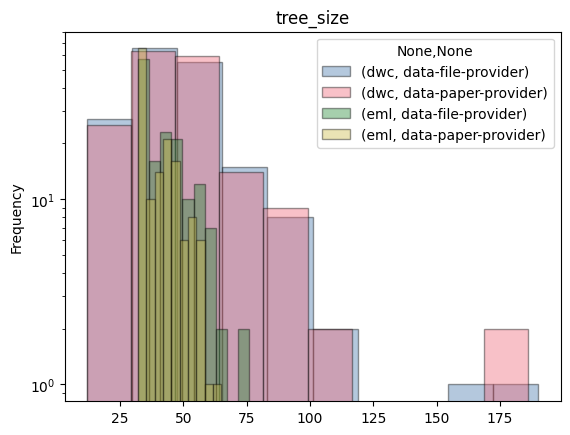

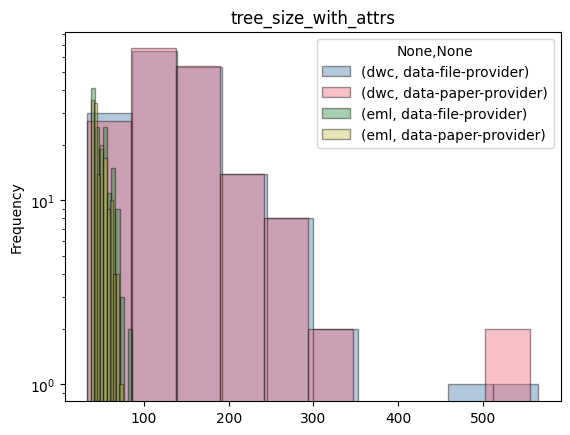

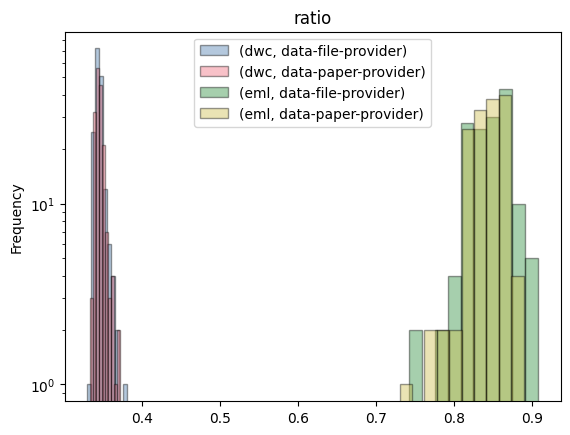

In [94]:
ax = None
for name,group in experiment_groups_tree:
    ax = group.plot.hist(y="tree_size", alpha=0.4, ax=ax, label=name, edgecolor="k", log=True)
    ax.set_title("tree_size")
plt.show()

ax = None
for name,group in experiment_groups_tree:
    ax = group.plot.hist(y="tree_size_with_attrs", alpha=0.4, ax=ax, label=name, edgecolor="k", log=True)
    ax.set_title("tree_size_with_attrs")
plt.show()

ax = None
for name,group in experiment_groups_tree:
    ax = (group["tree_size"] / group["tree_size_with_attrs"]).plot.hist(alpha=0.4, ax=ax, label=name, edgecolor="k", log=True)
    ax.legend()
    ax.set_title("ratio")

plt.show()

> **Correlation between parsing success and sample characterstics**

In [95]:
experiment_groups_tree[
    ["nr_data_files", "pdf_bytes", "log_pdf_bytes", "pdf_nr_pages", "parsed_int"]
].describe()

nr_data_files                                     \
                                    count      mean       std  min  25%  50%   
mschema treatment_repl                                                         
dwc     data-file-provider          179.0  1.569832  0.702632  1.0  1.0  1.0   
        data-paper-provider         179.0  1.569832  0.702632  1.0  1.0  1.0   
eml     data-file-provider          179.0  1.569832  0.702632  1.0  1.0  1.0   
        data-paper-provider         179.0  1.569832  0.702632  1.0  1.0  1.0   

                                      pdf_bytes                ...  \
                             75%  max     count          mean  ...   
mschema treatment_repl                                         ...   
dwc     data-file-provider   2.0  4.0     179.0  1.097365e+06  ...   
        data-paper-provider  2.0  4.0     179.0  1.097365e+06  ...   
eml     data-file-provider   2.0  4.0     179.0  1.097365e+06  ...   
        data-paper-provider  2.0  4.0     179.0  1.097365e+06  ...   

                            pdf_nr_pages       parsed_int                      \
                                     75%   max      count      mean       std   
mschema treatment_repl                                                          
dwc     data-file-provider          18.0  46.0      179.0  0.972067  0.165243   
        data-paper-provider         18.0  46.0      179.0  0.972067  0.165243   
eml     data-file-provider          18.0  46.0      179.0  0.837989  0.369495   
        data-paper-provider         18.0  46.0      179.0  0.826816  0.379468   

                                                      
                             min  25%  50%  75%  max  
mschema treatment_repl                                
dwc     data-file-provider   0.0  1.0  1.0  1.0  1.0  
        data-paper-provider  0.0  1.0  1.0  1.0  1.0  
eml     data-file-provider   0.0  1.0  1.0  1.0  1.0  
        data-paper-provider  0.0  1.0  1.0  1.0  1.0  

[4 rows x 40 columns]

In [96]:
experiment_groups_tree[
    ["nr_data_files", "pdf_bytes", "log_pdf_bytes", "pdf_nr_pages", "parsed_int"]
].corr("pearson")

nr_data_files  pdf_bytes  \
mschema treatment_repl                                                
dwc     data-file-provider  nr_data_files       1.000000   0.164903   
                            pdf_bytes           0.164903   1.000000   
                            log_pdf_bytes       0.181421   0.579863   
                            pdf_nr_pages        0.100086   0.077866   
                            parsed_int         -0.200847   0.009867   
        data-paper-provider nr_data_files       1.000000   0.164903   
                            pdf_bytes           0.164903   1.000000   
                            log_pdf_bytes       0.181421   0.579863   
                            pdf_nr_pages        0.100086   0.077866   
                            parsed_int         -0.007299  -0.069143   
eml     data-file-provider  nr_data_files       1.000000   0.164903   
                            pdf_bytes           0.164903   1.000000   
                            log_pdf_bytes       0.181421   0.579863   
                            pdf_nr_pages        0.100086   0.077866   
                            parsed_int          0.011364   0.035015   
        data-paper-provider nr_data_files       1.000000   0.164903   
                            pdf_bytes           0.164903   1.000000   
                            log_pdf_bytes       0.181421   0.579863   
                            pdf_nr_pages        0.100086   0.077866   
                            parsed_int          0.077220  -0.016647   

                                           log_pdf_bytes  pdf_nr_pages  \
mschema treatment_repl                                                   
dwc     data-file-provider  nr_data_files       0.181421      0.100086   
                            pdf_bytes           0.579863      0.077866   
                            log_pdf_bytes       1.000000      0.434693   
                            pdf_nr_pages        0.434693      1.000000   
                            parsed_int         -0.048940     -0.039847   
        data-paper-provider nr_data_files       0.181421      0.100086   
                            pdf_bytes           0.579863      0.077866   
                            log_pdf_bytes       1.000000      0.434693   
                            pdf_nr_pages        0.434693      1.000000   
                            parsed_int         -0.043839     -0.051419   
eml     data-file-provider  nr_data_files       0.181421      0.100086   
                            pdf_bytes           0.579863      0.077866   
                            log_pdf_bytes       1.000000      0.434693   
                            pdf_nr_pages        0.434693      1.000000   
                            parsed_int          0.067035      0.051561   
        data-paper-provider nr_data_files       0.181421      0.100086   
                            pdf_bytes           0.579863      0.077866   
                            log_pdf_bytes       1.000000      0.434693   
                            pdf_nr_pages        0.434693      1.000000   
                            parsed_int         -0.095348     -0.155957   

                                           parsed_int  
mschema treatment_repl                                 
dwc     data-file-provider  nr_data_files   -0.200847  
                            pdf_bytes        0.009867  
                            log_pdf_bytes   -0.048940  
                            pdf_nr_pages    -0.039847  
                            parsed_int       1.000000  
        data-paper-provider nr_data_files   -0.007299  
                            pdf_bytes       -0.069143  
                            log_pdf_bytes   -0.043839  
                            pdf_nr_pages    -0.051419  
                            parsed_int       1.000000  
eml     data-file-provider  nr_data_files    0.011364  
                            pdf_bytes        0.035015  
                            log_pdf_bytes    0.067035  
           

In [97]:
experiment_groups_tree[
    ["nr_data_files", "pdf_bytes", "log_pdf_bytes", "pdf_nr_pages", "parsed_int"]
].corr("spearman")

nr_data_files  pdf_bytes  \
mschema treatment_repl                                                
dwc     data-file-provider  nr_data_files       1.000000   0.093357   
                            pdf_bytes           0.093357   1.000000   
                            log_pdf_bytes       0.093357   1.000000   
                            pdf_nr_pages        0.148218   0.231727   
                            parsed_int         -0.204272  -0.031496   
        data-paper-provider nr_data_files       1.000000   0.093357   
                            pdf_bytes           0.093357   1.000000   
                            log_pdf_bytes       0.093357   1.000000   
                            pdf_nr_pages        0.148218   0.231727   
                            parsed_int          0.002944  -0.000656   
eml     data-file-provider  nr_data_files       1.000000   0.093357   
                            pdf_bytes           0.093357   1.000000   
                            log_pdf_bytes       0.093357   1.000000   
                            pdf_nr_pages        0.148218   0.231727   
                            parsed_int          0.020740   0.013645   
        data-paper-provider nr_data_files       1.000000   0.093357   
                            pdf_bytes           0.093357   1.000000   
                            log_pdf_bytes       0.093357   1.000000   
                            pdf_nr_pages        0.148218   0.231727   
                            parsed_int          0.085106  -0.090577   

                                           log_pdf_bytes  pdf_nr_pages  \
mschema treatment_repl                                                   
dwc     data-file-provider  nr_data_files       0.093357      0.148218   
                            pdf_bytes           1.000000      0.231727   
                            log_pdf_bytes       1.000000      0.231727   
                            pdf_nr_pages        0.231727      1.000000   
                            parsed_int         -0.031496     -0.042375   
        data-paper-provider nr_data_files       0.093357      0.148218   
                            pdf_bytes           1.000000      0.231727   
                            log_pdf_bytes       1.000000      0.231727   
                            pdf_nr_pages        0.231727      1.000000   
                            parsed_int         -0.000656     -0.091319   
eml     data-file-provider  nr_data_files       0.093357      0.148218   
                            pdf_bytes           1.000000      0.231727   
                            log_pdf_bytes       1.000000      0.231727   
                            pdf_nr_pages        0.231727      1.000000   
                            parsed_int          0.013645      0.058174   
        data-paper-provider nr_data_files       0.093357      0.148218   
                            pdf_bytes           1.000000      0.231727   
                            log_pdf_bytes       1.000000      0.231727   
                            pdf_nr_pages        0.231727      1.000000   
                            parsed_int         -0.090577     -0.157060   

                                           parsed_int  
mschema treatment_repl                                 
dwc     data-file-provider  nr_data_files   -0.204272  
                            pdf_bytes       -0.031496  
                            log_pdf_bytes   -0.031496  
                            pdf_nr_pages    -0.042375  
                            parsed_int       1.000000  
        data-paper-provider nr_data_files    0.002944  
                            pdf_bytes       -0.000656  
                            log_pdf_bytes   -0.000656  
                            pdf_nr_pages    -0.091319  
                            parsed_int       1.000000  
eml     data-file-provider  nr_data_files    0.020740  
                            pdf_bytes        0.013645  
                            log_pdf_bytes    0.013645  
           

In [98]:
from scipy.stats import pointbiserialr

for name,group in experiment_groups_tree:
    for column in ["nr_data_files", "pdf_bytes", "log_pdf_bytes", "pdf_nr_pages"]:
        r, p_val = pointbiserialr(group['parsed_int'], group[column])
        print(name, f"parsed_int-x-{column}", f"{r=}", f"{p_val=}")

('dwc', 'data-file-provider') parsed_int-x-nr_data_files r=np.float64(-0.20084675811517685) p_val=np.float64(0.007020968666406575)
('dwc', 'data-file-provider') parsed_int-x-pdf_bytes r=np.float64(0.009867257940245698) p_val=np.float64(0.8957015519177183)
('dwc', 'data-file-provider') parsed_int-x-log_pdf_bytes r=np.float64(-0.048940321230299934) p_val=np.float64(0.5153178695929145)
('dwc', 'data-file-provider') parsed_int-x-pdf_nr_pages r=np.float64(-0.03984650269586544) p_val=np.float64(0.5963994066887027)
('dwc', 'data-paper-provider') parsed_int-x-nr_data_files r=np.float64(-0.0072986035923415914) p_val=np.float64(0.9227535178411125)
('dwc', 'data-paper-provider') parsed_int-x-pdf_bytes r=np.float64(-0.06914348625341385) p_val=np.float64(0.35773102870350854)
('dwc', 'data-paper-provider') parsed_int-x-log_pdf_bytes r=np.float64(-0.043838776154145886) p_val=np.float64(0.560099287513452)
('dwc', 'data-paper-provider') parsed_int-x-pdf_nr_pages r=np.float64(-0.05141901321381022) p_val

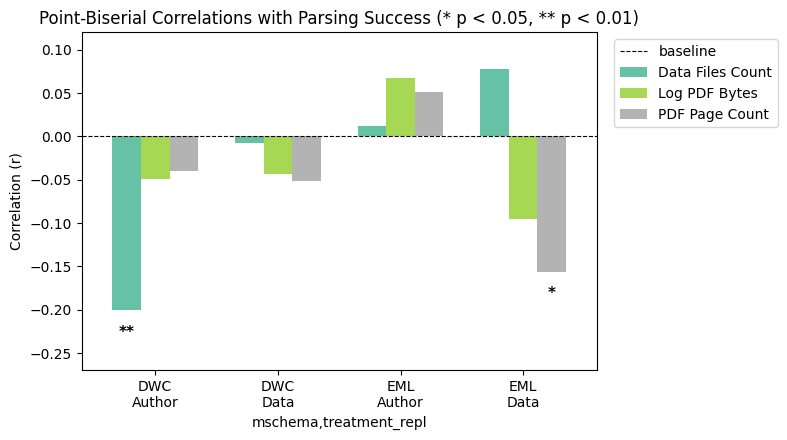

In [99]:
cols = ["nr_data_files", "log_pdf_bytes", "pdf_nr_pages"]
labels = ["baseline", "Data Files Count", "Log PDF Bytes", "PDF Page Count"]
corrs = experiment_groups_tree[cols + ["parsed_int"]].corr("pearson")["parsed_int"].unstack(level=-1).drop("parsed_int", axis=1)

ax = corrs[cols].plot(kind="bar", figsize=(8, 4.5), cmap="Set2", width=0.7)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xticklabels(["DWC\nAuthor", "DWC\nData", "EML\nAuthor", "EML\nData"], rotation=0)
ax.set_ylabel("Correlation (r)")
ax.set_ylim(-0.27, 0.12)
ax.legend(labels, bbox_to_anchor=(1.02, 1), loc="upper left")

# Compute and annotate significance stars (* p < 0.05, ** p < 0.01)
for g_idx, (name, group) in enumerate(experiment_groups_tree):
    for c_idx, col in enumerate(cols):
        r, p_val = pointbiserialr(group["parsed_int"], group[col])
        if p_val < 0.05:
            star = "**" if p_val < 0.01 else "*"
            bar_container = ax.containers[c_idx]
            bar = bar_container[g_idx]
            y_pos = bar.get_height() - 0.025 if bar.get_height() < 0 else bar.get_height() + 0.005
            ax.text(bar.get_x() + bar.get_width() / 2, y_pos, star, ha="center", va="center", fontweight="bold", fontsize=11)

plt.title("Point-Biserial Correlations with Parsing Success (* p < 0.05, ** p < 0.01)")
plt.tight_layout()
plt.show()

In [100]:
features = ["nr_data_files", "pdf_bytes", "log_pdf_bytes", "pdf_nr_pages"]
records = []

# Loop through each multi-index group (schema, treatment)
for (schema, treatment), group in experiment_groups_tree:
    for feat in features:
        r_pearson = group[feat].corr(group["parsed_int"], method="pearson")
        r_spearman = group[feat].corr(group["parsed_int"], method="spearman")
        r_pb, p_val = pointbiserialr(group["parsed_int"], group[feat])
        
        records.append({
            "schema": schema,
            "treatment": treatment,
            "feature": feat,
            "pearson_r": r_pearson,
            "spearman_rho": r_spearman,
            "point_biserial_r": r_pb,
            "p_value": p_val
        })

# Format as MultiIndex Matrix
matrix_df = pd.DataFrame(records).set_index(["schema", "treatment", "feature"])
matrix_df

pearson_r  spearman_rho  \
schema treatment           feature                                  
dwc    data-file-provider  nr_data_files  -0.200847     -0.204272   
                           pdf_bytes       0.009867     -0.031496   
                           log_pdf_bytes  -0.048940     -0.031496   
                           pdf_nr_pages   -0.039847     -0.042375   
       data-paper-provider nr_data_files  -0.007299      0.002944   
                           pdf_bytes      -0.069143     -0.000656   
                           log_pdf_bytes  -0.043839     -0.000656   
                           pdf_nr_pages   -0.051419     -0.091319   
eml    data-file-provider  nr_data_files   0.011364      0.020740   
                           pdf_bytes       0.035015      0.013645   
                           log_pdf_bytes   0.067035      0.013645   
                           pdf_nr_pages    0.051561      0.058174   
       data-paper-provider nr_data_files   0.077220      0.085106   
                           pdf_bytes      -0.016647     -0.090577   
                           log_pdf_bytes  -0.095348     -0.090577   
                           pdf_nr_pages   -0.155957     -0.157060   

                                          point_biserial_r   p_value  
schema treatment           feature                                    
dwc    data-file-provider  nr_data_files         -0.200847  0.007021  
                           pdf_bytes              0.009867  0.895702  
                           log_pdf_bytes         -0.048940  0.515318  
                           pdf_nr_pages          -0.039847  0.596399  
       data-paper-provider nr_data_files         -0.007299  0.922754  
                           pdf_bytes             -0.069143  0.357731  
                           log_pdf_bytes         -0.043839  0.560099  
                           pdf_nr_pages          -0.051419  0.494245  
eml    data-file-provider  nr_data_files          0.011364  0.879995  
                           pdf_bytes              0.035015  0.641696  
                           log_pdf_bytes          0.067035  0.372617  
                           pdf_nr_pages           0.051561  0.493051  
       data-paper-provider nr_data_files          0.077220  0.304220  
                           pdf_bytes             -0.016647  0.824959  
                           log_pdf_bytes         -0.095348  0.204219  
                           pdf_nr_pages          -0.155957  0.037094

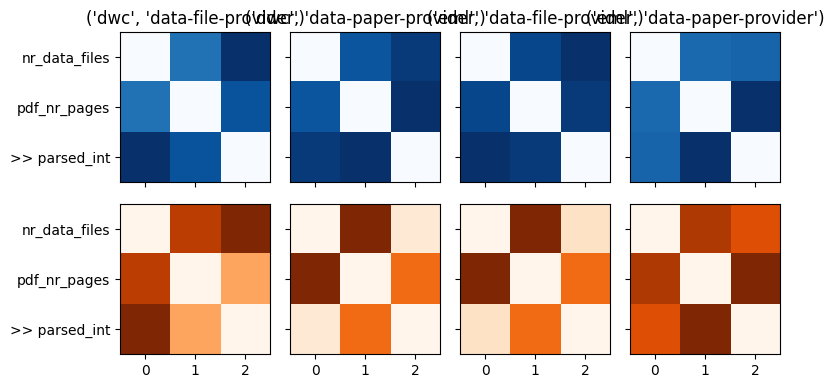

In [101]:
fig, axs = plt.subplots(2,4, figsize=(8,4), sharey=True, sharex=True)

for tax, bax, (name, group) in zip(axs[0], axs[1], experiment_groups_tree[
    ["nr_data_files", "pdf_bytes", "log_pdf_bytes", "pdf_nr_pages", "parsed_int"]
]):
    tax.set_title(name)
    tax.set_yticks([0,1,2], labels=["nr_data_files", "pdf_nr_pages", ">> parsed_int"])
    tax.imshow(
        group[["nr_data_files", "pdf_nr_pages", "parsed_int"]].corr("pearson"),
        cmap="Blues_r"
    )
    bax.imshow(
        group[["nr_data_files", "pdf_nr_pages", "parsed_int"]].corr(method=lambda x,y: pointbiserialr(x,y)[1]),
        cmap="Oranges_r"
    )


plt.tight_layout()
plt.show()

> **Node details**

In [102]:
%%sql experiment_tree_info_nodes << 
SELECT * 
FROM experiment_constructed_tree_info_nodes
ORDER BY case_id ASC;

Running query in 'duckdb'

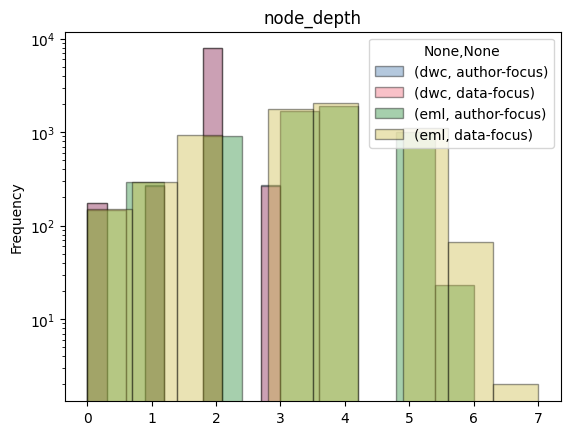

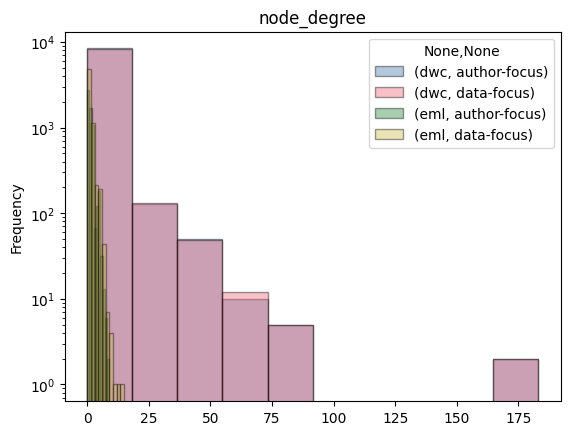

In [103]:
experiment_groups_node = experiment_tree_info_nodes.groupby(["mschema", "treatment"])

ax = None
for name,group in experiment_groups_node:
    ax = group.plot.hist(y="node_depth", alpha=0.4, ax=ax, label=name, edgecolor="k", log=True)
    ax.set_title("node_depth")
ax = None
for name,group in experiment_groups_node:
    ax = group.plot.hist(y="node_degree", alpha=0.4, ax=ax, label=name, edgecolor="k", log=True)
    ax.set_title("node_degree")

plt.show()

## Step 3: $COR$ metric

> **Syntactical correspondence** to a metadata schema:

$$
COR(\hat{m},s) = 1 - \frac{|{\epsilon_{s}(\hat{m})}|}{size_{+a}(\hat{m})}
$$

In [149]:
dwc_validator = matls.get_xmlschema_validator('http://rs.tdwg.org/dwc/text/tdwg_dwc_text.xsd')
eml_validator = matls.get_xmlschema_validator('https://eml.ecoinformatics.org/eml-2.2.0/eml.xsd')

/Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/terms/' from ['http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd': Forbidden.
  return self.schema_class(
/Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/elements/1.1/' from ['http://dublincore.org/schemas/xmls/qdc/dc.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/dc.xsd': Forbidden.
  return self.schema_class(


In [168]:
class ValidationError(TypedDict):
    reason: str
    error_kind: str

class ValidationInfo(TypedDict):
    completed_ok: bool
    is_valid_xml: bool
    error_count: int
    validation_errors: list[ValidationError]

INCORRECT_VALIDATION = {
    "completed_ok": False,
    "is_valid_xml": False,
    "error_count": 0,
    "validation_errors": []
}

def validation_response_to_info(validated) -> ValidationInfo:
    if isinstance(validated, tuple):
        return {
            "completed_ok": True,
            "is_valid_xml": validated[0] and not validated[1],
            "error_count": len(validated[1]),
            "validation_errors": [
                {"reason": error.reason, "error_kind": error.__class__.__name__}
                for error in validated[1]
            ]
        }
    return INCORRECT_VALIDATION

In [169]:
def validate_xml_json(outcome_json: str, validator) -> str:
    outcome_dict = json.loads(outcome_json)
    if ('resolutions' not in outcome_dict):
        return json.dumps({'parsed': False, 'tree_info': None, 'error': "'resolutions' key is not found"})
    try:
        wc_metadata_xml = resolve_xml_content(outcome_dict)
        wc_metadata_xml_clean = cleanup_special_characters(cleanup_gap_failures(wc_metadata_xml))
        validation = validator.validate(wc_metadata_xml_clean)
        return json.dumps(validation_response_to_info(validation))
    except Exception as e:
        return json.dumps(INCORRECT_VALIDATION)

In [170]:
def validate_dwc_xml_json(outcome_json: str) -> str:
    return validate_xml_json(outcome_json, dwc_validator)

def validate_eml_xml_json(outcome_json: str) -> str:
    return validate_xml_json(outcome_json, eml_validator)

In [171]:
for f in [
    validate_dwc_xml_json, validate_eml_xml_json
]:
    try:
        conn.remove_function(f.__name__)
    except Exception as e:
        print(f"Function not found: {e}")
    conn.create_function(f.__name__, f)

In [175]:
%%sql
SELECT 
    e.*,
    -- schema validation
    validate_dwc_xml_json(outcome_json) as validation_json,
    json_extract(validation_json, '$.completed_ok')::BOOLEAN as validation_completed_ok,
    json_extract(validation_json, '$.is_valid_xml')::BOOLEAN as validation_is_valid_xml,
    json_extract(validation_json, '$.error_count')::INT as validation_error_count,
    json_extract(validation_json, '$.validation_errors')::JSON as validation_errors_json,
    (1 - ((validation_error_count) / (e.tree_size_with_attrs))) AS metric_COR
FROM experiment_constructed_tree_info_grand e
WHERE mschema = 'dwc'
    AND validation_completed_ok
    AND NOT validation_is_valid_xml

Running query in 'duckdb'

,case_id,mschema,treatment,treatment_repl,nr_data_files,pdf_bytes,pdf_nr_pages,ddir,success,outcome_json,...,parsed_int,tree_size,tree_size_with_attrs,tree_nodes,validation_json,validation_completed_ok,validation_is_valid_xml,validation_error_count,validation_errors_json,metric_COR
0,134,dwc,data-focus,data-file-provider,3,4238745,11,working_copy/data/162-59bab4f6-af5e-350c-a491-...,True,"{""messages"": [], ""settings"": {""runtime_config""...",...,1,190,565,"[{""tag"":""{http://rs.tdwg.org/dwc/text/}archive...","{""completed_ok"": true, ""is_valid_xml"": false, ...",True,False,2,"[{""reason"":""attribute index='not-derived-003':...",0.99646


In [176]:
%%sql
SELECT 
    e.*,
    -- schema validation
    validate_dwc_xml_json(outcome_json) as validation_json,
    json_extract(validation_json, '$.completed_ok')::BOOLEAN as validation_completed_ok,
    json_extract(validation_json, '$.is_valid_xml')::BOOLEAN as validation_is_valid_xml,
    json_extract(validation_json, '$.error_count')::INT as validation_error_count,
    json_extract(validation_json, '$.validation_errors')::JSON as validation_errors_json,
    (1 - ((validation_error_count) / (e.tree_size_with_attrs))) AS metric_COR
FROM experiment_constructed_tree_info_grand e
WHERE mschema = 'eml'
    AND validation_completed_ok
    AND NOT validation_is_valid_xml

Running query in 'duckdb'

,case_id,mschema,treatment,treatment_repl,nr_data_files,pdf_bytes,pdf_nr_pages,ddir,success,outcome_json,...,parsed_int,tree_size,tree_size_with_attrs,tree_nodes,validation_json,validation_completed_ok,validation_is_valid_xml,validation_error_count,validation_errors_json,metric_COR
0,0,eml,data-focus,data-file-provider,2,486786,14,working_copy/data/000-6f97bcef-7324-3425-bb72-...,True,"{""messages"": [], ""settings"": {""runtime_config""...",...,1,38,46,"[{""tag"":""{https://eml.ecoinformatics.org/eml-2...","{""completed_ok"": true, ""is_valid_xml"": false, ...",True,False,1,"[{""reason"":""'{https://eml.ecoinformatics.org/e...",0.978261
1,0,eml,author-focus,data-paper-provider,2,486786,14,working_copy/data/000-6f97bcef-7324-3425-bb72-...,True,"{""messages"": [], ""settings"": {""runtime_config""...",...,1,47,55,"[{""tag"":""{https://eml.ecoinformatics.org/eml-2...","{""completed_ok"": true, ""is_valid_xml"": false, ...",True,False,1,"[{""reason"":""'{https://eml.ecoinformatics.org/e...",0.981818
2,2,eml,data-focus,data-file-provider,2,408932,18,working_copy/data/002-325b19cf-6c16-3147-b8db-...,True,"{""messages"": [], ""settings"": {""runtime_config""...",...,1,61,69,"[{""tag"":""{https://eml.ecoinformatics.org/eml-2...","{""completed_ok"": true, ""is_valid_xml"": false, ...",True,False,1,"[{""reason"":""'{https://eml.ecoinformatics.org/e...",0.985507
3,3,eml,data-focus,data-file-provider,2,918075,20,working_copy/data/003-d72b6b4f-0fb1-301e-81d0-...,True,"{""messages"": [], ""settings"": {""runtime_config""...",...,1,50,64,"[{""tag"":""{https://eml.ecoinformatics.org/eml-2...","{""completed_ok"": true, ""is_valid_xml"": false, ...",True,False,1,"[{""reason"":""'{https://eml.ecoinformatics.org/e...",0.984375
4,4,eml,data-focus,data-file-provider,3,516962,19,working_copy/data/004-93ed8a30-2f05-37c7-a371-...,True,"{""messages"": [], ""settings"": {""runtime_config""...",...,1,45,55,"[{""tag"":""{https://eml.ecoinformatics.org/eml-2...","{""completed_ok"": true, ""is_valid_xml"": false, ...",True,False,1,"[{""reason"":""'{https://eml.ecoinformatics.org/e...",0.981818
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
293,174,eml,author-focus,data-paper-provider,2,554637,22,working_copy/data/208-8395f577-f4ec-3cc9-9d46-...,True,"{""messages"": [], ""settings"": {""runtime_config""...",...,1,34,41,"[{""tag"":""{https://eml.ecoinformatics.org/eml-2...","{""completed_ok"": true, ""is_valid_xml"": false, ...",True,False,1,"[{""reason"":""'{https://eml.ecoinformatics.org/e...",0.975610
294,167,eml,author-focus,data-paper-provider,1,202577,6,working_copy/data/200-cedf0556-5a05-3267-ac67-...,True,"{""messages"": [], ""settings"": {""runtime_config""...",...,1,48,55,"[{""tag"":""{https://eml.ecoinformatics.org/eml-2...","{""completed_ok"": true, ""is_valid_xml"": false, ...",True,False,1,"[{""reason"":""'{https://eml.ecoinformatics.org/e...",0.981818
295,175,eml,author-focus,data-paper-provider,1,526047,15,working_copy/data/209-1cf45154-9800-31c6-ba38-...,True,"{""messages"": [], ""settings"": {""runtime_config""...",...,1,32,38,"[{""tag"":""{https://eml.ecoinformatics.org/eml-2...","{""completed_ok"": true, ""is_valid_xml"": false, ...",True,False,1,"[{""reason"":""'{https://eml.ecoinformatics.org/e...",0.973684
296,176,eml,author-focus,data-paper-provider,1,187818,14,working_copy/data/210-99ee49cb-8bcd-39a4-895b-...,True,"{""messages"": [], ""settings"": {""runtime_config""...",...,1,34,42,"[{""tag"":""{https://eml.ecoinformatics.org/eml-2...","{""completed_ok"": true, ""is_valid_xml"": false, ...",True,False,1,"[{""reason"":""'{https://eml.ecoinformatics.org/e...",0.976190


## Step 4: $STS$ metric

> **Structural tree similarity** between constructed and ground-truth metadata instances:

$$
STS({\hat{m}}, m) = 1 - \frac{APTED({\hat{m}},{m})}{size_{+a}({\hat{m}})+ size_{+a}({m})}
$$

## Step 5: $SVS_{text}$ metric

> **Semantic value similarity** _for **text**_ contents of nodes between constructed and ground-truth metadata instances:

$$
    \phi=text \mid SVS_{\phi}(\hat{m},m)=1-\frac{
        \sum_{\hat{n},n\in{N_{SP}(\hat{m},m)}}{
            \cos^{-1}(S_{C}(\phi(\hat{n}), \phi(n)))
        }
    }{
        \pi\cdot|SP(\hat{m},m)|
    }
$$

## Step 6: $SVS_{attr}$ metric

> **Semantic value similarity** _for attribute_ contents of nodes between constructed and ground-truth metadata instances:

$$
    \phi=attr \mid SVS_{\phi}(\hat{m},m)=1-\frac{
        \sum_{\hat{n},n\in{N_{SP}(\hat{m},m)}}{
            \cos^{-1}(S_{C}(\phi(\hat{n}), \phi(n)))
        }
    }{
        \pi\cdot|SP(\hat{m},m)|
    }
$$

## Step 7: $AIB$ metric

> **Architect involvement balance** in the metadata construction task:

$$
AIB(\hat{m},s,d) = 1 - \frac{|plan(s,d)|}{size_{+a}(\hat{m})}
$$

In [ ]:
%%sql architect_involvement_balance <<
CREATE OR REPLACE TABLE architect_involvement_balance AS (
    SELECT 
        case_id, 
        mschema, 
        replace(
            replace(treatment, 'data-focus', 'data-file-provider'),
            'author-focus', 'data-paper-provider'
        ) as treatment_repl,
        concat(mschema, '-x-', treatment_repl) group_tag,
        d.success,
        d.parsed,
        tree_size_with_attrs,
        json_array_length(json_extract(
            d.outcome_json, 
            '$.resolutions[0].verified_gap_derivation_plan.gaps'
        )) AS plan_size,
        (
            1 - (plan_size / tree_size_with_attrs)
        ) AS architect_involvement_balance
    FROM experiment_constructed_tree_info_grand AS d
    WHERE d.parsed::BOOL
);
SELECT * FROM architect_involvement_balance;

In [ ]:
experiment_groups = architect_involvement_balance.groupby(["group_tag"])
experiment_groups["architect_involvement_balance"].describe()

In [ ]:
(
    (
        ("df", 0.993769 - 0.988217),
        ("dp", 0.993856 - 0.988889), 
    ),
    (
        ("df", 0.748941 - 0.631847),
        ("dp", 0.736097 - 0.634146), 
    )
)

In [ ]:
experiment_groups_dir = {name[0]: group for name, group in experiment_groups}

In [ ]:
for name, group in experiment_groups:
    np.log1p(group["architect_involvement_balance"]).plot.hist(alpha=0.7, edgecolor="k")

In [ ]:
# AIB distribution is non-normal
for name, group in experiment_groups:
    display(f"{name[0]=}")
    display(group.describe(include="all").to_latex())
    display(normaltest(group["architect_involvement_balance"]))
    display(normaltest(np.log1p(group["architect_involvement_balance"])))

In [ ]:
display(
    mannwhitneyu(
        experiment_groups_dir["dwc-x-data-file-provider"]["architect_involvement_balance"],
        experiment_groups_dir["dwc-x-data-paper-provider"]["architect_involvement_balance"],
        alternative="greater"
    )
)

In [ ]:
display(
    mannwhitneyu(
        experiment_groups_dir["eml-x-data-file-provider"]["architect_involvement_balance"],
        experiment_groups_dir["eml-x-data-paper-provider"]["architect_involvement_balance"],
        alternative="greater"
    )
)

### Plan Insights

In [ ]:
import re
from lxml import etree

# Define global constant for sanitized namespace replacement
SAMPLE_NS_PREFIX = "http://gap-placeholder.invalid/"

def sanitize_xmlns_gaps(xml_str):
    pattern = r'(xmlns(?::[a-zA-Z0-9_]+)?\s*=\s*["\'])([^"\']*\{gap___[A-Za-z0-9_]+___gap\}[^"\']*)(["\'])'
    
    def replacer(match):
        prefix, gap_val, suffix = match.groups()
        safe_uri = SAMPLE_NS_PREFIX + gap_val
        return f"{prefix}{safe_uri}{suffix}"
        
    return re.sub(pattern, replacer, xml_str)

def find_gap_context_lxml(xml_string, target_gap):
    gap_uri_target = SAMPLE_NS_PREFIX + target_gap
    parser = etree.XMLParser(recover=True)
    
    root = etree.fromstring(xml_string.encode('utf-8'), parser=parser)
    for elem in root.iter():
        tag_name = etree.QName(elem).localname

        # 1. Check Namespace Declarations (xmlns)
        for ns_prefix, ns_url in elem.nsmap.items():
            if ns_url and (target_gap in ns_url or gap_uri_target in ns_url):
                attr_name = f"xmlns:{ns_prefix}" if ns_prefix else "xmlns"
                return {
                    "enclosing_tag": tag_name,
                    "type": "namespace_attribute",
                    "attribute_name": attr_name
                }

        # 2. Check Standard Attributes
        for attr_name, attr_val in elem.attrib.items():
            clean_attr = etree.QName(attr_name).localname
            if target_gap in attr_val or gap_uri_target in attr_val:
                return {
                    "enclosing_tag": tag_name,
                    "type": "attribute",
                    "attribute_name": clean_attr
                }

        # 3. Check Text Nodes
        if elem.text and target_gap in elem.text:
            return {
                "enclosing_tag": tag_name,
                "type": "element_text",
                "attribute_name": 'n/a',
            }

    return {"enclosing_tag": None, "type": None, "attribute_name": None}

In [ ]:
import re
import xml.etree.ElementTree as ET

SAMPLE_NS_PREFIX = "http://gap-placeholder.invalid/"

def remove_gap_braces(xml_str: str) -> str:
    return xml_str.replace("{{", "__").replace("}}", '__')

def sanitize_xmlns_gaps(xml_str: str) -> str:
    pattern = r'(xmlns(?::[a-zA-Z0-9_]+)?\s*=\s*["\'])([^"\']*\{\{GAP_[^\}\}]+\}\}[^"\']*)(["\'])'
    
    def replacer(match):
        prefix, gap_val, suffix = match.groups()
        safe_uri = SAMPLE_NS_PREFIX + gap_val
        return f"{prefix}{safe_uri}{suffix}"
        
    return re.sub(pattern, replacer, xml_str)

def get_element_path(elem: ET.Element, parent_map: dict) -> str:
    """Helper to trace path from root element to the given element."""
    if elem is None:
        return None
    path = []
    curr = elem
    while curr is not None:
        tag_name = curr.tag.split('}')[-1] if '}' in curr.tag else curr.tag
        path.append(tag_name)
        curr = parent_map.get(curr)
    return "/" + "/".join(reversed(path))

def find_gap_context_etree(xml_string: str, target_gap: str) -> dict:
    gap_uri_target = SAMPLE_NS_PREFIX + target_gap
    
    sanitized_xml = sanitize_xmlns_gaps(xml_string)
    root = ET.fromstring(sanitized_xml)
    
    # Map each child element to its immediate parent node
    parent_map = {child: parent for parent in root.iter() for child in parent}

    for elem in root.iter():
        tag_name = elem.tag.split('}')[-1] if '}' in elem.tag else elem.tag
        current_path = get_element_path(elem, parent_map)

        # 1. Check Namespace Declarations / Tag Names
        if target_gap in elem.tag or gap_uri_target in elem.tag:
            return {
                "enclosing_tag": tag_name,
                "type": "namespace_attribute",
                "attribute_name": "xmlns",
                "enclosing_path": current_path
            }

        # 2. Check Standard Attributes
        for attr_name, attr_val in elem.attrib.items():
            clean_attr = attr_name.split('}')[-1] if '}' in attr_name else attr_name
            if target_gap in attr_val or gap_uri_target in attr_val:
                return {
                    "enclosing_tag": tag_name,
                    "type": "attribute",
                    "attribute_name": clean_attr,
                    "enclosing_path": current_path
                }

        # 3. Check Text Content (Inside <elem>...</elem>)
        if elem.text and target_gap in elem.text:
            return {
                "enclosing_tag": tag_name,
                "type": "element_text",
                "attribute_name": 'n/a',
                "enclosing_path": current_path
            }

        # 4. Check Tail Text (Text after </elem> before parent closure or sibling)
        if elem.tail and target_gap in elem.tail:
            parent = parent_map.get(elem)
            parent_tag = (parent.tag.split('}')[-1] if '}' in parent.tag else parent.tag) if parent is not None else root.tag
            parent_path = get_element_path(parent, parent_map) if parent is not None else current_path
            return {
                "enclosing_tag": parent_tag,
                "type": "element_text",
                "attribute_name": 'n/a',
                "enclosing_path": parent_path
            }

    return {"enclosing_tag": None, "type": None, "attribute_name": None, "enclosing_path": None}

In [ ]:
def find_gap_context_json(tree_string: str, target_gap: str) -> str:
    clean_tree_string = sanitize_xmlns_gaps(cleanup_special_characters(remove_gap_braces(tree_string)))
    context = find_gap_context_etree(clean_tree_string, remove_gap_braces(target_gap))
    return json.dumps(context)

In [ ]:
try:
    conn.remove_function("find_gap_context_json")
except Exception as e:
    print(e)
conn.create_function("find_gap_context_json", find_gap_context_json)

In [ ]:
%%sql plan_details <<
CREATE OR REPLACE TABLE plan_details AS (
    SELECT 
        d.case_id,
        d.mschema, 
        d.treatment,
        replace(
            replace(d.treatment, 'data-focus', 'data-file-provider'),
            'author-focus', 'data-paper-provider'
        ) as treatment_repl,
        concat(d.mschema, '-x-', treatment_repl) AS group_tag,
        d.success,
        d.parsed,
        d.outcome_json,
        pgs.*,
        json_extract_string(pgs.value, '$.gap_id') AS gap_id,
        json_extract_string(pgs.value, '$.gap_type') AS gap_type,
        json_extract_string(pgs.value, '$.gap_description') AS gap_description,
        json_extract_string(pgs.value, '$.gap_replacement_pattern') AS gap_replacement_pattern,
        json_extract_string(pgs.value, '$.gap_scope_files') AS gap_scope_files,
        json_extract_string(pgs.value, '$.gap_derivation_request') AS gap_derivation_request,
        split(split(gap_replacement_pattern, ':')[3], '}}')[1] AS gap_replacement_pattern_tag,
        split(trim(gap_replacement_pattern, '"'), ':')[1] AS gap_replacement_pattern_id,
        json_extract_string(
            d.outcome_json, 
            '$.resolutions[0].architect_xml_blueprint.content'
        ) AS architect_xml_blueprint,
        json_extract_string(
            d.outcome_json, 
            '$.resolutions[0].working_copy_xml_blueprint.content'
        ) AS working_copy_xml_blueprint,
        -- find_gap_context_json(architect_xml_blueprint, gap_id) AS gap_context,
        find_gap_context_json(architect_xml_blueprint, gap_replacement_pattern)  AS gap_context,
        json_extract_string(gap_context, '$.enclosing_tag') AS gap_enclosing_tag,
        json_extract_string(gap_context, '$.type') AS gap_context_type,
        json_extract_string(gap_context, '$.attribute_name') AS gap_enclosing_attribute_name,
        json_extract_string(gap_context, '$.enclosing_path') AS gap_enclosing_path,
    
        find_gap_context_json(architect_xml_blueprint, gap_replacement_pattern_id)  AS gap_context_by_id,
        json_extract_string(gap_context_by_id, '$.enclosing_tag') AS gap_enclosing_tag_by_id,
        json_extract_string(gap_context_by_id, '$.type') AS gap_context_type_by_id,
        json_extract_string(gap_context_by_id, '$.attribute_name') AS gap_enclosing_attribute_name_by_id,
    FROM experiment_constructed_tree_info_grand AS d,
        json_each(json_extract(
            d.outcome_json, 
            '$.resolutions[0].verified_gap_derivation_plan.gaps'
        )) AS pgs,
    WHERE d.parsed::BOOL
    ORDER BY d.case_id, group_tag
);
SELECT * FROM plan_details;

In [ ]:
plan_details.describe(include="all")

In [ ]:
%%sql failed_plan_details <<
SELECT * 
FROM plan_details
WHERE gap_context_type IS NULL AND gap_context_type_by_id IS NULL

In [ ]:
%%sql diverging_plan_details <<
SELECT * 
FROM plan_details
WHERE gap_context <> gap_context_by_id
    AND gap_context_type IS NOT NULL AND gap_context_type_by_id IS NOT NULL

In [ ]:
%%sql aligned_plan_details <<
SELECT * 
FROM plan_details
WHERE gap_context = gap_context_by_id
    AND gap_context_type IS NOT NULL AND gap_context_type_by_id IS NOT NULL

In [ ]:
%%sql correct_plan_details_percentage <<
WITH aligned_count_per_case_per_group AS (
    SELECT case_id, group_tag, count(*) AS count_aligned
    FROM plan_details
    WHERE gap_context = gap_context_by_id
        AND gap_context_type IS NOT NULL AND gap_context_type_by_id IS NOT NULL
    GROUP BY 1,2
), all_plan_details AS (
    SELECT case_id, group_tag, count(*) AS count_total
    FROM plan_details
    GROUP BY 1,2
), joined_plan_details AS (
    SELECT a.case_id, a.group_tag, a.count_aligned, t.count_total
    FROM aligned_count_per_case_per_group AS a
        JOIN all_plan_details AS t
            ON a.case_id = t.case_id AND a.group_tag = t.group_tag
) 
SELECT case_id, group_tag, (count_aligned / count_total * 100) AS aligned_percentage
FROM joined_plan_details 

In [ ]:
%%sql 
WITH aligned_count_per_case_per_group AS (
    SELECT case_id, group_tag, count(*) AS count_aligned
    FROM plan_details
    WHERE gap_context = gap_context_by_id
        AND gap_context_type IS NOT NULL AND gap_context_type_by_id IS NOT NULL
    GROUP BY 1,2
), all_plan_details AS (
    SELECT case_id, group_tag, count(*) AS count_total
    FROM plan_details
    GROUP BY 1,2
), joined_plan_details AS (
    SELECT a.case_id, a.group_tag, a.count_aligned, t.count_total, (a.count_aligned = t.count_total)::INT AS aligned_count
    FROM aligned_count_per_case_per_group AS a
        JOIN all_plan_details AS t
            ON a.case_id = t.case_id AND a.group_tag = t.group_tag
), aligned_percentage AS (
    SELECT 
        group_tag, 
        SUM(aligned_count) AS count_fully_aligned, 
        COUNT(1) as count_total, 
    FROM joined_plan_details 
    GROUP BY 1
    ORDER BY group_tag
)
SELECT group_tag, (count_fully_aligned / count_total) * 100 AS aligned_percentage
FROM aligned_percentage

In [ ]:
correct_plan_details_percentage.groupby(["group_tag"]).describe()

In [ ]:
correct_plan_details_percentage[
    correct_plan_details_percentage["aligned_percentage"] < 100.00
].groupby(["group_tag"])["aligned_percentage"].describe()

In [ ]:
correct_plan_details_percentage[
    correct_plan_details_percentage["aligned_percentage"] < 100.00
].groupby(["group_tag"])["aligned_percentage"].plot.hist(
    alpha=0.5, edgecolor="k", legend=True, 
)

In [ ]:
failed_plan_details.describe()

In [ ]:
diverging_plan_details.describe()

In [ ]:
failed_plan_details

In [ ]:
print(failed_plan_details["case_id"].to_list()[0])
print("---")
print(failed_plan_details["outcome_json"].to_list()[0])
print("---")
print(failed_plan_details["gap_id"].to_list()[0])
print("---")
print(failed_plan_details["gap_replacement_pattern"].to_list()[0])
print("---")
print(failed_plan_details["gap_replacement_pattern_id"].to_list()[0])
print("---")
print(failed_plan_details["architect_xml_blueprint"].to_list()[0])
print("---")
print(failed_plan_details["working_copy_xml_blueprint"].to_list()[0])

In [ ]:
failed_plan_details.fillna(0).groupby(
    [
        "group_tag", 
        "gap_enclosing_tag", "gap_enclosing_attribute_name", 
        "gap_enclosing_tag_by_id", "gap_enclosing_attribute_name_by_id",
    ]
).count()

In [ ]:
diverging_plan_details

In [ ]:
diverging_plan_details.fillna(0).groupby(
    [
        "group_tag", 
        "gap_replacement_pattern",
        "gap_id",
        "gap_description",
        "gap_enclosing_tag", "gap_enclosing_attribute_name", 
        "gap_enclosing_tag_by_id", "gap_enclosing_attribute_name_by_id",
    ]
).count()

In [ ]:
diverging_plan_details.groupby(
    [
        "group_tag", 
        "gap_enclosing_tag", "gap_enclosing_attribute_name", 
        "gap_enclosing_tag_by_id", "gap_enclosing_attribute_name_by_id",
    ]
).count() 

In [ ]:
aligned_plan_details.groupby(
    [
        "group_tag", 
        "gap_enclosing_tag", "gap_enclosing_attribute_name", 
        "gap_enclosing_tag_by_id", "gap_enclosing_attribute_name_by_id",
    ]
).count() 

In [ ]:
plan_details.groupby(
    [
        "group_tag", 
        "gap_enclosing_tag", "gap_enclosing_attribute_name", 
        "gap_enclosing_tag_by_id", "gap_enclosing_attribute_name_by_id",
    ]
).count()

In [ ]:
aligned_plan_details.groupby(
    [
        "group_tag", 
        "gap_context_type",
        "gap_enclosing_tag", "gap_enclosing_attribute_name", 
        "gap_enclosing_tag_by_id", "gap_enclosing_attribute_name_by_id",
    ]
).count()

In [ ]:
aligned_plan_details[
    aligned_plan_details["mschema"] == "dwc"
].groupby(
    [
        "group_tag", 
        "gap_context_type",
        "gap_enclosing_tag", "gap_enclosing_attribute_name", 
        "gap_enclosing_tag_by_id", "gap_enclosing_attribute_name_by_id",
    ]
).count()

In [ ]:
%%sql
WITH archive_occuring AS (
    SELECT group_tag, case_id, gap_enclosing_tag, COUNT(1) AS count_occurence, (COUNT(1) > 0)::INT AS has_occurrence
    FROM aligned_plan_details
    WHERE gap_enclosing_attribute_name = 'metadata'
    GROUP BY 1,2,3
    ORDER BY has_occurrence DESC
)
SELECT 
    group_tag, 
    SUM(has_occurrence), 
    mean(count_occurence), 
    stddev(count_occurence), 
    MAX(count_occurence), 
    median(count_occurence),
    (SUM(has_occurrence) / 174 * 100) AS occurs_percentage
FROM archive_occuring AS ao
GROUP BY group_tag
ORDER BY group_tag

In [ ]:
%%sql
WITH archive_occuring AS (
    SELECT group_tag, case_id, gap_enclosing_tag, COUNT(1) AS count_occurence, (COUNT(1) > 0)::INT AS has_occurrence
    FROM aligned_plan_details
    WHERE gap_enclosing_attribute_name = 'term'
    GROUP BY 1,2,3
    ORDER BY has_occurrence DESC
)
SELECT 
    group_tag, 
    SUM(has_occurrence), 
    mean(count_occurence), 
    stddev(count_occurence), 
    MAX(count_occurence), 
    median(count_occurence),
    (SUM(has_occurrence) / 174 * 100) AS occurs_percentage
FROM archive_occuring AS ao
GROUP BY group_tag
ORDER BY group_tag

In [ ]:
%%sql
WITH archive_occuring AS (
    SELECT group_tag, case_id, gap_enclosing_tag, COUNT(1) AS count_occurence, (COUNT(1) > 0)::INT AS has_occurrence
    FROM aligned_plan_details
    WHERE gap_enclosing_attribute_name = 'rowType'
    GROUP BY 1,2,3
    ORDER BY has_occurrence DESC
)
SELECT 
    group_tag, 
    SUM(has_occurrence), 
    mean(count_occurence), 
    stddev(count_occurence), 
    MAX(count_occurence), 
    median(count_occurence),
    (SUM(has_occurrence) / 174 * 100) AS occurs_percentage
FROM archive_occuring AS ao
GROUP BY group_tag
ORDER BY group_tag

In [ ]:
%%sql
WITH archive_occuring AS (
    SELECT group_tag, case_id, gap_enclosing_tag, COUNT(1) AS count_occurence, (COUNT(1) > 0)::INT AS has_occurrence
    FROM aligned_plan_details
    WHERE gap_enclosing_attribute_name = 'index'
    GROUP BY 1,2,3
    ORDER BY has_occurrence DESC
)
SELECT 
    group_tag, 
    SUM(has_occurrence), 
    mean(count_occurence), 
    stddev(count_occurence), 
    MAX(count_occurence), 
    median(count_occurence),
    (SUM(has_occurrence) / 174 * 100) AS occurs_percentage
FROM archive_occuring AS ao
GROUP BY group_tag
ORDER BY group_tag

In [ ]:
%%sql
SELECT group_tag, gap_context_type, COUNT(1)
FROM aligned_plan_details
WHERE mschema = 'eml'
GROUP by 1,2

In [ ]:
%%sql
SELECT group_tag, gap_enclosing_tag, COUNT(1) AS count_occurrence
FROM aligned_plan_details
WHERE mschema = 'eml'
    AND treatment_repl = 'data-file-provider'
    AND gap_context_type = 'element_text'
GROUP by 1,2
ORDER BY count_occurrence DESC
LIMIT 15

In [ ]:
%%sql
SELECT group_tag, gap_enclosing_tag, COUNT(1) AS count_occurrence
FROM aligned_plan_details
WHERE mschema = 'eml'
    AND treatment_repl = 'data-paper-provider'
    AND gap_context_type = 'element_text'
GROUP by 1,2
ORDER BY count_occurrence DESC
LIMIT 15

In [ ]:
import re
import pandas as pd


def map_eml_path_to_category(path: str, tag: str = "") -> str:
    """Maps an EML gap_enclosing_path (and optional tag) to one of four EML categories:

    (c1) attribution
    (c2) study description
    (c3) spatio-temporal elements
    (c4) biodiversity classification
    """
    path_lower = str(path).lower()
    tag_lower = str(tag).lower()

    # (c4) Biodiversity classification
    if any(
        term in path_lower
        for term in [
            "taxonomic",
            "taxon",
            "species",
            "triatominae",  # Domain-specific dataset context in your tail
        ]
    ):
        return "c4"

    # (c3) Spatio-temporal elements
    if any(
        term in path_lower
        for term in [
            "studyareadescription",
            "geographiccoverage",
            "temporalcoverage",
            "eventdaterange",
            "enddate",
            "startdate",
            "date",
            "spatial",
            "temporal",
            "observedcontext",
        ]
    ):
        return "c3"

    # (c1) Attribution
    if any(
        term in path_lower
        for term in [
            "creator",
            "personnel",
            "contact",
            "individualname",
            "surname",
            "givenname",
            "userid",
            "funding",
            "organizationname",
            "publisher",
            "associatedparty",
            "role",
            "license",
            "accessrights",
        ]
    ):
        return "c1"

    # (c2) Study description
    if any(
        term in path_lower
        for term in [
            "methodstep",
            "methods",
            "qualitycontrol",
            "instrumentation",
            "sampling",
            "designdescription",
            "maintenance",
            "abstract",
            "title",
            "descriptor",
            "provenance",
            "processing",
            "laboratoryanalysis",
        ]
    ) or tag_lower in ["title", "abstract", "instrumentation"]:
        return "c2"

    
    # (c+) Additional Metadata
    if any(
        term in path_lower
        for term in [
            "additionalmetadata"
        ]
    ):
        return "c+"
    
    # Fallback default for unmatched custom metadata
    return "other / unmapped"


# Example application to a DataFrame:
def categorize_eml_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    """Adds a 'category' column to the dataset based on gap_enclosing_path and

    gap_enclosing_tag.
    """
    df_copy = df.copy()
    df_copy["category"] = df_copy.apply(
        lambda row: map_eml_path_to_category(
            row["gap_enclosing_path"], row.get("gap_enclosing_tag", "")
        ),
        axis=1,
    )
    return df_copy

In [ ]:
%%sql eml_dfp_most_frequent_tags <<
SELECT group_tag, gap_enclosing_tag, gap_enclosing_path, COUNT(1) AS count_occurrence
FROM aligned_plan_details
WHERE mschema = 'eml'
    AND treatment_repl = 'data-file-provider'
    AND gap_context_type = 'element_text'
GROUP by 1,2,3
ORDER BY group_tag, count_occurrence DESC

In [ ]:
display(eml_dfp_most_frequent_tags.head(150))
display(eml_dfp_most_frequent_tags.describe(include="all").to_latex())
display(eml_dfp_most_frequent_tags.head(50).to_latex())

In [ ]:
eml_dfp_most_frequent_tags_cats = categorize_eml_dataframe(eml_dfp_most_frequent_tags)
eml_dfp_most_frequent_tags_cats.groupby("category").count()

In [ ]:
eml_dfp_most_frequent_tags_cats.groupby("category").describe()

In [ ]:
eml_dfp_most_frequent_tags_cats[
    eml_dfp_most_frequent_tags_cats["category"] == "c4"
]

In [ ]:
%%sql eml_dpp_most_frequent_tags <<
SELECT group_tag, gap_enclosing_tag, gap_enclosing_path, COUNT(1) AS count_occurrence
FROM aligned_plan_details
WHERE mschema = 'eml'
    AND treatment_repl = 'data-paper-provider'
    AND gap_context_type = 'element_text'
GROUP by 1,2,3
ORDER BY group_tag, count_occurrence DESC

In [ ]:
display(eml_dpp_most_frequent_tags.head(50))
display(eml_dpp_most_frequent_tags.describe(include="all").to_latex())
display(eml_dpp_most_frequent_tags.head(50).to_latex())

In [ ]:
eml_dpp_most_frequent_tags_cats = categorize_eml_dataframe(eml_dpp_most_frequent_tags)
eml_dpp_most_frequent_tags_cats.groupby("category").count()

In [ ]:
eml_dpp_most_frequent_tags_cats.groupby("category").describe()

In [ ]:
eml_dpp_most_frequent_tags_cats[
    eml_dpp_most_frequent_tags_cats["category"] == "c+"
]

In [ ]:
%%sql
SELECT group_tag, gap_enclosing_attribute_name, COUNT(1) AS count_occurrence
FROM aligned_plan_details
WHERE mschema = 'eml'
    -- AND treatment_repl = 'data-paper-provider'
    AND contains(gap_context_type, 'attribute')
GROUP by 1,2
ORDER BY count_occurrence DESC

In [ ]:
for name, group in aligned_plan_details.groupby(
    [
        "group_tag", 
    ]
):
    print("---")
    print(f"{name=}")
    display(group.groupby(["gap_context_type"]).count())
    display(group.groupby(["gap_context_type", "gap_enclosing_tag"]).count())
    # group.groupby(["gap_context_type", "gap_enclosing_tag"]).count()["case_id"].plot.barh()
    # plt.show()
    
    display(group[
            group["gap_context_type"] == "attribute"
    ].groupby(
        ["gap_context_type", "gap_enclosing_tag", "gap_enclosing_attribute_name"]
    ).count())

    # group[
    #         (group["gap_context_type"].str.contains("attribute"))
    # ].groupby(
    #     ["gap_context_type", "gap_enclosing_tag", "gap_enclosing_attribute_name"]
    # ).count()["case_id"].plot.barh()
    # plt.show()

    
    display(group[
            group["gap_context_type"] == "element_text"
    ].groupby(
        ["gap_context_type", "gap_enclosing_tag", "gap_enclosing_attribute_name"]
    ).count())
    # group[
    #         group["gap_context_type"] == "element_text"
    # ].groupby(
    #     ["gap_context_type", "gap_enclosing_tag", "gap_enclosing_attribute_name"]
    # ).count().plot.barh()
    # plt.show()

    